In [9]:
# Task 1 - Data Preparation and Feature Engineering

%pip -q install "pandas==2.2.3" "numpy==2.2.6" "requests==2.32.4" yfinance matplotlib scipy

In [10]:
#Import libraries and set the study period.

from pathlib import Path
from datetime import datetime, timezone
from io import StringIO
import time, json, platform, importlib.metadata
import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
from IPython.display import display

START = pd.Timestamp('2021-01-01')
END_EXCL = pd.Timestamp('2025-01-01')
BENCHMARK = '^GSPC'
MIN_COVERAGE = 0.95
MIN_ALIGNED_WEEKS = 52
BATCH_SIZE = 35
OBSERVATION_UTC = datetime.now(timezone.utc).isoformat()
OUT = Path('/content/task1_outputs') if Path('/content').exists() else Path.cwd() / 'task1_outputs'
OUT.mkdir(parents=True, exist_ok=True)

VERSIONS = {m: importlib.metadata.version(m) for m in ['pandas','numpy','yfinance','requests','matplotlib','scipy']}
VERSIONS.update({'python': platform.python_version(), 'retrieval_utc': OBSERVATION_UTC,
                 'start_inclusive': str(START.date()), 'end_exclusive': str(END_EXCL.date()),
                 'benchmark': BENCHMARK, 'daily_coverage_threshold': MIN_COVERAGE,
                 'min_aligned_weekly_returns': MIN_ALIGNED_WEEKS})
(OUT / 'run_metadata.json').write_text(json.dumps(VERSIONS, indent=2))
print('Output folder:', OUT)
print('Source capture time (UTC):', OBSERVATION_UTC)
print('Package versions:', VERSIONS)

Output folder: /content/task1_outputs
Source capture time (UTC): 2026-11-22T06:38:54.959112+00:00
Package versions: {'pandas': '2.2.3', 'numpy': '2.2.6', 'yfinance': '1.8.0', 'requests': '2.32.4', 'matplotlib': '3.11.2', 'scipy': '1.18.1', 'python': '3.13.18', 'retrieval_utc': '2026-11-22T06:38:54.959112+00:00', 'start_inclusive': '2021-01-01', 'end_exclusive': '2025-01-01', 'benchmark': '^GSPC', 'daily_coverage_threshold': 0.95, 'min_aligned_weekly_returns': 52}


In [11]:
# Task 1.1 - Ticker Selection and Data Acquisition
# Get and save the current S&P 500 ticker list

WIKI_URL = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
resp = requests.get(WIKI_URL, headers={'User-Agent': 'Mozilla/5.0 (educational research)'}, timeout=30)
resp.raise_for_status()
wikipedia_retrieved_utc = datetime.now(timezone.utc).isoformat()
companies = pd.read_html(StringIO(resp.text))[0]
assert {'Symbol', 'Security', 'GICS Sector'}.issubset(companies.columns), companies.columns.tolist()
companies = companies[['Symbol', 'Security', 'GICS Sector']].copy()
companies['Ticker'] = (companies['Symbol'].astype(str).str.strip()
                       .str.replace('.', '-', regex=False))
assert companies['Ticker'].is_unique
companies.to_csv(OUT / 'sp500_constituents_snapshot.csv', index=False)
(OUT / 'ticker_source.json').write_text(json.dumps({
    'url': WIKI_URL, 'retrieved_utc': wikipedia_retrieved_utc,
    'count': len(companies), 'membership_caveat': 'current S&P 500 constituents, not the 2021 population'
}, indent=2))
tickers = companies['Ticker'].tolist()
print('Tickers:', len(tickers), '| sample:')
display(companies.head())

Tickers: 503 | sample:


,Symbol,Security,GICS Sector,Ticker
0,MMM,3M,Industrials,MMM
1,AOS,A. O. Smith,Industrials,AOS
2,ABT,Abbott Laboratories,Health Care,ABT
3,ABBV,AbbVie,Health Care,ABBV
4,ACN,Accenture,Information Technology,ACN


In [12]:
# Download historical daily prices, adjusted prices, volume, and the S&P 500 benchmark.
QUOTE_FIELDS = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']
CACHE_FILE = None

# This normalizer accepts both supported MultiIndex orientations from yfinance.
def unpack_download(raw: pd.DataFrame, symbols: list[str]) -> list[pd.DataFrame]:
    output = []
    if raw is None or raw.empty:
        return output
    for symbol in symbols:
        if isinstance(raw.columns, pd.MultiIndex):
            if symbol in raw.columns.get_level_values(0):
                part = raw.xs(symbol, axis=1, level=0).copy()
            elif symbol in raw.columns.get_level_values(-1):
                part = raw.xs(symbol, axis=1, level=-1).copy()
            else:
                continue
        elif len(symbols) == 1:
            part = raw.copy()
        else:
            raise ValueError('Unexpected non-MultiIndex multi-symbol response; inspect data source.')
        if isinstance(part.columns, pd.MultiIndex):
            raise ValueError(f'Unexpected nested columns for {symbol}: {part.columns}')
        part = part.reindex(columns=QUOTE_FIELDS)
        if not {'Close','Adj Close','Volume'}.issubset(part.dropna(axis=1, how='all').columns):
            continue
        part.index = pd.DatetimeIndex(part.index).tz_localize(None).normalize()
        part = part.rename_axis('Date').reset_index()
        part = part[(part['Date'] >= START) & (part['Date'] < END_EXCL)]
        part = part.dropna(subset=['Close','Adj Close','Volume'], how='all')
        if part.empty:
            continue
        part.insert(1, 'Ticker', symbol)
        output.append(part)
    return output

if CACHE_FILE:
    quotes = pd.read_csv(CACHE_FILE, parse_dates=['Date'])
    required = {'Date','Ticker','Close','Adj Close','Volume'}
    if not required.issubset(quotes):
        raise ValueError('Cached snapshot lacks mandatory fields: ' + str(required - set(quotes)))
    quotes = quotes[(quotes['Date'] >= START) & (quotes['Date'] < END_EXCL)].copy()
    print('Loaded documented cached data; verify the file source and dates:', CACHE_FILE)
else:
    chunks, failed_batches = [], []
    all_symbols = tickers + [BENCHMARK]
    for start_at in range(0, len(all_symbols), BATCH_SIZE):
        batch = all_symbols[start_at:start_at + BATCH_SIZE]
        try:
            raw = yf.download(batch, start=START.strftime('%Y-%m-%d'),
                              end=END_EXCL.strftime('%Y-%m-%d'),
                              interval='1d', auto_adjust=False, actions=True,
                              group_by='ticker', multi_level_index=True,
                              progress=False, threads=True, timeout=30)
            chunks.extend(unpack_download(raw, batch))
            found = {f['Ticker'].iloc[0] for f in chunks}
            print(f'Batch {start_at // BATCH_SIZE + 1}: {len(set(batch) & found)} of {len(batch)} found')
        except Exception as exc:
            failed_batches.append({'batch': batch, 'error': str(exc)})
            print('Batch failed:', batch[:2], '...', str(exc)[:100])
        time.sleep(0.7)
    if failed_batches:
        (OUT / 'failed_batches.json').write_text(json.dumps(failed_batches, indent=2))
    if not chunks:
        raise RuntimeError('No stock data downloaded. Check Colab internet, Yahoo availability, or a documented cache.')
    quotes = pd.concat(chunks, ignore_index=True)

quotes['Date'] = pd.to_datetime(quotes['Date']).dt.tz_localize(None).dt.normalize()
for field in QUOTE_FIELDS:
    if field not in quotes:
        quotes[field] = np.nan
    quotes[field] = pd.to_numeric(quotes[field], errors='coerce')
quotes = quotes.sort_values(['Ticker','Date']).reset_index(drop=True)
quotes.to_csv(OUT / 'daily_quotes_original.csv.gz', index=False, compression='gzip')
print('Raw daily rows:', len(quotes), '| downloaded symbols:', quotes['Ticker'].nunique())
print('Date range:', quotes['Date'].min(), 'to', quotes['Date'].max())
assert BENCHMARK in quotes['Ticker'].unique(), 'Benchmark ^GSPC is missing; stop and inspect source.'
display(quotes.head())

Batch 1: 35 of 35 found
Batch 2: 35 of 35 found
Batch 3: 35 of 35 found
Batch 4: 35 of 35 found
Batch 5: 35 of 35 found


ERROR:yfinance:$FDXF: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Batch 6: 34 of 35 found


ERROR:yfinance:$HONA: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Batch 7: 34 of 35 found
Batch 8: 35 of 35 found
Batch 9: 35 of 35 found
Batch 10: 35 of 35 found


ERROR:yfinance:$Q: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


... (2 outputs left out)

Batch 12: 34 of 35 found
Batch 13: 35 of 35 found


ERROR:yfinance:$VYLR: Data doesn't exist for startDate = 1609477200, endDate = 1735707600
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: Data doesn't exist for startDate = 1609477200, endDate = 1735707600


Batch 14: 34 of 35 found
Batch 15: 14 of 14 found
Raw daily rows: 497309 | downloaded symbols: 499
Date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00


Price,Date,Ticker,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
0,2021-01-04,A,118.940002,120.089996,117.110001,118.639999,114.009117,2030700.0,0.194,0.0
1,2021-01-05,A,118.480003,120.320000,118.070000,119.610001,114.941254,2344000.0,0.000,0.0
2,2021-01-06,A,118.690002,123.879997,118.209999,122.889999,118.093231,2428500.0,0.000,0.0
3,2021-01-07,A,124.330002,127.480003,124.110001,126.160004,121.235603,1775900.0,0.000,0.0
4,2021-01-08,A,126.489998,127.639999,125.849998,127.059998,122.100464,1577200.0,0.000,0.0


In [13]:
# Task 1.2 - Data Validation and Alignment
# Check missing values, invalid prices, volumes, dates, and data coverage.
required_columns = {'Ticker','Date','Close','Adj Close','Volume'}
assert required_columns.issubset(quotes), required_columns - set(quotes)
duplicates = quotes[quotes.duplicated(['Ticker','Date'], keep=False)]
duplicates.to_csv(OUT / 'duplicate_date_rows.csv', index=False)
if len(duplicates):
    raise ValueError(f'{len(duplicates)} duplicate ticker-date rows found. Inspect before removing any.')

numeric_ok = (np.isfinite(quotes['Close']) & (quotes['Close'] > 0) &
              np.isfinite(quotes['Adj Close']) & (quotes['Adj Close'] > 0) &
              np.isfinite(quotes['Volume']) & (quotes['Volume'] >= 0))
invalid_rows = quotes.loc[~numeric_ok].copy()
invalid_rows.to_csv(OUT / 'invalid_daily_rows.csv', index=False)
clean = quotes.loc[numeric_ok].copy()

# Preserve raw data; compute quality flags on raw and valid data independently.
audit = quotes.groupby('Ticker').agg(
    raw_rows=('Date','size'),
    nonpositive_or_missing_close=('Close', lambda s: int((s.isna() | (s <= 0)).sum())),
    nonpositive_or_missing_adjusted=('Adj Close', lambda s: int((s.isna() | (s <= 0)).sum())),
    negative_or_missing_volume=('Volume', lambda s: int((s.isna() | (s < 0)).sum())),
    zero_volume_days=('Volume', lambda s: int((s == 0).sum())),
    split_events=('Stock Splits', lambda s: int((s.fillna(0) != 0).sum())),
    dividends=('Dividends', lambda s: int((s.fillna(0) != 0).sum()))
).reset_index()

market = clean[clean['Ticker'].eq(BENCHMARK)].set_index('Date').sort_index()
if len(market) < 800:
    raise ValueError('Benchmark has unexpectedly few daily dates; inspect Yahoo source before continuing.')
market_dates = pd.DatetimeIndex(market.index.unique()).sort_values()
observation_date = market_dates.max()
assert START <= observation_date < END_EXCL

# Coverage is measured against the benchmark's recorded market sessions.
per_share = []
for ticker in tickers:
    s = clean[clean['Ticker'].eq(ticker)].sort_values('Date')
    dates = pd.DatetimeIndex(s['Date'])
    present = dates.isin(market_dates).sum()
    per_share.append({
        'Ticker': ticker,
        'valid_daily_rows': len(s),
        'market_sessions_observed': int(present),
        'market_sessions_total': len(market_dates),
        'daily_coverage': present / len(market_dates),
        'first_valid_date': s['Date'].min() if len(s) else pd.NaT,
        'last_valid_date': s['Date'].max() if len(s) else pd.NaT,
        'has_observation_date': bool(observation_date in dates),
        'last_80_sessions_complete': bool(pd.Index(market_dates[-80:]).isin(dates).all())
    })
coverage = pd.DataFrame(per_share)
audit = companies[['Ticker','Security','GICS Sector']].merge(coverage, on='Ticker', how='left').merge(audit, on='Ticker', how='left')

# Large adjusted-price changes may reflect market moves, errors, or corporate actions.
price_jump = clean.sort_values(['Ticker','Date']).copy()
price_jump['AdjustedDailyReturn'] = price_jump.groupby('Ticker')['Adj Close'].pct_change(fill_method=None)
suspect_jumps = price_jump.loc[price_jump['AdjustedDailyReturn'].abs() > 0.50]
suspect_jumps.to_csv(OUT / 'price_jumps_review.csv', index=False)
audit.to_csv(OUT / 'daily_validation_audit.csv', index=False)
clean.to_csv(OUT / 'daily_quotes_valid.csv.gz', index=False, compression='gzip')
print('Observation date:', observation_date.date(), '| benchmark sessions:', len(market_dates))
print('Invalid daily rows:', len(invalid_rows), '| adjusted-price jumps >50%:', len(suspect_jumps))
print('Shares with >=95% daily coverage:', int((coverage.daily_coverage >= MIN_COVERAGE).sum()))
display(audit.head())

Observation date: 2024-12-31 | benchmark sessions: 1005
Invalid daily rows: 0 | adjusted-price jumps >50%: 4
Shares with >=95% daily coverage: 489


,Ticker,Security,GICS Sector,valid_daily_rows,market_sessions_observed,market_sessions_total,daily_coverage,first_valid_date,last_valid_date,has_observation_date,last_80_sessions_complete,raw_rows,nonpositive_or_missing_close,nonpositive_or_missing_adjusted,negative_or_missing_volume,zero_volume_days,split_events,dividends
0,MMM,3M,Industrials,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,1.0,16.0
1,AOS,A. O. Smith,Industrials,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,0.0,16.0
2,ABT,Abbott Laboratories,Health Care,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,0.0,16.0
3,ABBV,AbbVie,Health Care,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,0.0,16.0
4,ACN,Accenture,Information Technology,1005,1005,1005,1.0,2021-01-04,2024-12-31,True,True,1005.0,0.0,0.0,0.0,0.0,0.0,16.0


In [14]:
# Task 1.3 - Weekly Return and Weekly Beta
# Task 1.3.1 - Mean Weekly Return
# Task 1.3.2 - Weekly Beta
# Calculate Friday-ending returns and compare each stock with the benchmark.
def complete_calendar_fridays(weekly_index: pd.DatetimeIndex, start: pd.Timestamp,
                              end_exclusive: pd.Timestamp) -> pd.DatetimeIndex:
    """Keep Mon–Fri calendar weeks wholly inside [start, end_exclusive)."""
    fridays = pd.DatetimeIndex(weekly_index)
    week_mondays = fridays - pd.Timedelta(days=4)
    return fridays[(week_mondays >= start) & (fridays < end_exclusive)]

def paired_weekly_metrics(stock_returns: pd.Series, market_returns: pd.Series, min_weeks=52):
    paired = pd.concat([stock_returns.rename('stock'), market_returns.rename('market')], axis=1).dropna()
    n = len(paired)
    if n < min_weeks or paired['market'].var(ddof=1) <= 0:
        return {'MeanWeeklyReturn': np.nan, 'WeeklyBeta': np.nan, 'AlignedWeeks': n}
    return {'MeanWeeklyReturn': paired['stock'].mean(),
            'WeeklyBeta': paired['stock'].cov(paired['market']) / paired['market'].var(ddof=1),
            'AlignedWeeks': n}

# Task 01.3.1 - Convert adjusted daily closing prices to weekly returns.
wide_adj = clean.pivot(index='Date', columns='Ticker', values='Adj Close').reindex(market_dates)
weekly_price = wide_adj.resample('W-FRI').last()
full_weeks = complete_calendar_fridays(weekly_price.index, START, END_EXCL)
weekly_price = weekly_price.loc[full_weeks].copy()
weekly_returns = weekly_price.pct_change(fill_method=None)
if BENCHMARK not in weekly_returns:
    raise ValueError('Missing benchmark in weekly return matrix')

# Task 01.3.2 - Calculate each share's mean weekly return and weekly beta.
risk_results = []
for ticker in tickers:
    if ticker not in weekly_returns.columns:
        risk_results.append({'Ticker': ticker, 'MeanWeeklyReturn': np.nan,
                             'WeeklyBeta': np.nan, 'AlignedWeeks': 0})
        continue
    metrics = paired_weekly_metrics(weekly_returns[ticker], weekly_returns[BENCHMARK], MIN_ALIGNED_WEEKS)
    risk_results.append({'Ticker': ticker, **metrics})
risk = pd.DataFrame(risk_results)
weekly_price.to_csv(OUT / 'weekly_adjusted_price.csv')
weekly_returns.to_csv(OUT / 'weekly_returns.csv')
risk.to_csv(OUT / 'weekly_risk_features.csv', index=False)
print('Full calendar weeks:', len(weekly_price), '| weekly return dates:',
      weekly_returns.index.min().date(), 'through', weekly_returns.index.max().date())
print('Paired weekly metrics for first rows:')
display(risk.head())

Full calendar weeks: 208 | weekly return dates: 2021-01-08 through 2024-12-27
Paired weekly metrics for first rows:


,Ticker,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks
0,MMM,0.001142,0.869079,207
1,AOS,0.001991,1.042804,207
2,ABT,0.000971,0.583543,207
3,ABBV,0.003749,0.425366,207
4,ACN,0.002376,1.143300,207


In [15]:
# Task 1.4 - Adapted RFM Calculations
# Task 1.4.1 - Recency
# Task 1.4.2 - Frequency
# Task 1.4.3 - Monetary
# Identify unusual volume using the previous 20 sessions: calculate the RFM features.
# Check if today's volume is more than twice the previous 20-session average.
def unusual_volume_flags(volume: pd.Series) -> pd.DataFrame:
    """Input indexed on the full market-session calendar; never fill missing volumes."""
    volume = pd.to_numeric(volume, errors='coerce').astype(float)
    preceding_20_mean = volume.shift(1).rolling(window=20, min_periods=20).mean()
    threshold = 2 * preceding_20_mean
    event = (volume > threshold) & preceding_20_mean.notna() & volume.notna()
    return pd.DataFrame({'Volume': volume, 'Prior20MeanVolume': preceding_20_mean,
                         'Threshold': threshold, 'HighVolumeEvent': event})

def compute_rfm(stock_daily: pd.DataFrame, calendar: pd.DatetimeIndex,
                observation: pd.Timestamp) -> tuple[dict, pd.DataFrame]:
    """Return an auditable stock's RFM and its aligned daily event timeline."""
    s = stock_daily.set_index('Date').sort_index().reindex(calendar)
    if len(calendar) < 80:
        return {'R': np.nan,'F': np.nan,'M_USD': np.nan,
                'RFM_Status': 'Fewer than 80 benchmark sessions', 'LastHighVolumeDate': pd.NaT}, pd.DataFrame()
    last80 = s.iloc[-80:]
    if last80[['Close','Volume']].isna().any().any():
        return {'R': np.nan,'F': np.nan,'M_USD': np.nan,
                'RFM_Status': 'Incomplete final 80 market sessions', 'LastHighVolumeDate': pd.NaT}, pd.DataFrame()
    timeline = unusual_volume_flags(s['Volume'])
    timeline['Close'] = s['Close']
    timeline['ApproxDailyTradedUSD'] = s['Close'] * s['Volume']
    history_events = timeline.index[timeline['HighVolumeEvent']]
    latest_event = history_events.max() if len(history_events) else pd.NaT
    # Task 1.4.1 - Recency: Calendar days since the most recent unusual-volume day.
    R = (observation - latest_event).days if pd.notna(latest_event) else np.nan
    final60 = timeline.iloc[-60:]
    # Task 1.4.2 - Frequency: Count unusual-volume days in the final 60 sessions.
    F = int(final60['HighVolumeEvent'].sum())
    # Task 1.4.3 - Monetary: Sum Close multiplied by Volume in the final 60 sessions.
    M = float(final60['ApproxDailyTradedUSD'].sum(min_count=60))
    status = 'Valid' if pd.notna(R) else 'No qualifying historical event'
    return {'R': R,'F': F,'M_USD': M,
            'RFM_Status': status, 'LastHighVolumeDate': latest_event}, timeline

rfm_results = []
example_ticker = 'AAPL' if 'AAPL' in tickers else tickers[0]
example_timeline = None
for ticker in tickers:
    d = clean.loc[clean['Ticker'].eq(ticker), ['Date','Close','Volume']].copy()
    metrics, timeline = compute_rfm(d, market_dates, observation_date)
    rfm_results.append({'Ticker': ticker, **metrics})
    if ticker == example_ticker:
        example_timeline = timeline
rfm = pd.DataFrame(rfm_results)
rfm.to_csv(OUT / 'rfm_features_all_shares.csv', index=False)
print('RFM eligible:', int(rfm.RFM_Status.eq('Valid').sum()),
      '| no qualifying event:', int(rfm.RFM_Status.eq('No qualifying historical event').sum()))
display(rfm.head())

# Task 1.4 - Save a worked RFM example for one share.
if example_timeline is not None and not example_timeline.empty:
    worked = example_timeline.iloc[-80:].copy()
    worked.index.name = 'Date'
    worked['Window60'] = [False] * 20 + [True] * 60
    worked.to_csv(OUT / f'{example_ticker}_rfm_worked_example_80_sessions.csv')
    print(f'Worked audit: {example_ticker}; last 80 dates and event rule (note first 20 are baseline)')
    display(worked.tail(12))
    display(rfm[rfm['Ticker'].eq(example_ticker)])

RFM eligible: 498 | no qualifying event: 0


,Ticker,R,F,M_USD,RFM_Status,LastHighVolumeDate
0,MMM,11.0,4.0,2.599146e+10,Valid,2024-12-20
1,AOS,11.0,2.0,4.748980e+09,Valid,2024-12-20
2,ABT,11.0,1.0,3.523027e+10,Valid,2024-12-20
3,ABBV,11.0,3.0,6.837054e+10,Valid,2024-12-20
4,ACN,11.0,2.0,5.199430e+10,Valid,2024-12-20


Worked audit: AAPL; last 80 dates and event rule (note first 20 are baseline)


,Volume,Prior20MeanVolume,Threshold,HighVolumeEvent,Close,ApproxDailyTradedUSD,Window60
Date,,,,,,,
2024-12-13,33155300.0,42754595.0,85509190.0,False,248.130005,8.226825e+09,True
2024-12-16,51694800.0,42166165.0,84332330.0,False,251.039993,1.297746e+10,True
2024-12-17,51356400.0,42354720.0,84709440.0,False,253.479996,1.301782e+10,True
2024-12-18,56774100.0,42690855.0,85381710.0,False,248.050003,1.408282e+10,True
2024-12-19,60882300.0,43718970.0,87437940.0,False,249.789993,1.520779e+10,True
2024-12-20,147495300.0,45004605.0,90009210.0,True,254.490005,3.753608e+10,True
2024-12-23,40858800.0,50273955.0,100547910.0,False,255.270004,1.043003e+10,True
2024-12-24,23234700.0,50408480.0,100816960.0,False,258.200012,5.999200e+09,True
2024-12-26,27237100.0,47062575.0,94125150.0,False,259.019989,7.054953e+09,True


,Ticker,R,F,M_USD,RFM_Status,LastHighVolumeDate
38,AAPL,11.0,2.0,6.233034e+11,Valid,2024-12-20


In [16]:
# Task 1.5 - Metric Interpretation and Supporting Evidence
# Save feature summaries, the final share list, and reasons for exclusions.
feature_all = (companies[['Ticker','Security','GICS Sector']]
               .merge(coverage, on='Ticker', how='left')
               .merge(risk, on='Ticker', how='left')
               .merge(rfm, on='Ticker', how='left'))

def reasons_for(row):
    reasons=[]
    if not np.isfinite(row['daily_coverage']) or row['daily_coverage'] == 0:
        reasons.append('No valid downloaded daily data')
    elif row['daily_coverage'] < MIN_COVERAGE:
        reasons.append(f'Daily coverage below {MIN_COVERAGE:.0%}')
    if not row['has_observation_date']:
        reasons.append('Missing final benchmark observation date')
    if not row['last_80_sessions_complete']:
        reasons.append('Incomplete last 80 market sessions')
    if pd.isna(row['AlignedWeeks']) or row['AlignedWeeks'] < MIN_ALIGNED_WEEKS:
        reasons.append('Insufficient aligned weekly returns')
    if pd.isna(row['MeanWeeklyReturn']) or pd.isna(row['WeeklyBeta']):
        reasons.append('Undefined weekly return or beta')
    if row['RFM_Status'] != 'Valid':
        reasons.append(str(row['RFM_Status']))
    return '; '.join(reasons) if reasons else 'Included'

feature_all['InclusionDecision'] = feature_all.apply(reasons_for, axis=1)
feature_all['Included'] = feature_all['InclusionDecision'].eq('Included')
feature_all.to_csv(OUT / 'share_inclusion_and_exclusion_log.csv', index=False)
features = feature_all.loc[feature_all['Included']].copy()
required_features = ['MeanWeeklyReturn','WeeklyBeta','R','F','M_USD']
assert not features[required_features].isna().any().any(), 'Investigate missing required features'
assert features['Ticker'].is_unique
features.to_csv(OUT / 'task1_common_feature_table.csv', index=False)

print('Source tickers:', len(tickers))
print('Included for BOTH Task 2 feature matrices:', len(features))
print('Excluded:', len(feature_all) - len(features))
print('Reason frequencies:')
print(feature_all.loc[~feature_all['Included'], 'InclusionDecision'].value_counts().head(15))
print('Feature summaries (raw units; weekly mean return is a decimal fraction):')
display(features[required_features].describe().T)
display(features[['Ticker','Security','GICS Sector'] + required_features].head(10))

Source tickers: 503
Included for BOTH Task 2 feature matrices: 489
Excluded: 14
Reason frequencies:
InclusionDecision
Daily coverage below 95%                                                                                                                                                                                                   6
No valid downloaded daily data; Missing final benchmark observation date; Incomplete last 80 market sessions; Insufficient aligned weekly returns; Undefined weekly return or beta; Incomplete final 80 market sessions    5
Daily coverage below 95%; Insufficient aligned weekly returns; Undefined weekly return or beta                                                                                                                             3
Name: count, dtype: int64
Feature summaries (raw units; weekly mean return is a decimal fraction):


,count,mean,std,min,25%,50%,75%,max
MeanWeeklyReturn,489.0,2.864153e-03,2.647811e-03,-4.468094e-03,1.182857e-03,2.635541e-03,4.207596e-03,1.777248e-02
WeeklyBeta,489.0,9.736009e-01,4.061762e-01,5.545223e-02,6.666519e-01,9.480432e-01,1.179165e+00,3.778560e+00
R,489.0,2.037014e+01,2.128524e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.500000e+01,2.220000e+02
F,489.0,2.987730e+00,1.327458e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M_USD,489.0,3.925106e+10,1.287563e+11,1.297483e+09,1.025033e+10,1.665860e+10,3.201227e+10,1.847697e+12


,Ticker,Security,GICS Sector,MeanWeeklyReturn,WeeklyBeta,R,F,M_USD
0,MMM,3M,Industrials,0.001142,0.869079,11.0,4.0,2.599146e+10
1,AOS,A. O. Smith,Industrials,0.001991,1.042804,11.0,2.0,4.748980e+09
2,ABT,Abbott Laboratories,Health Care,0.000971,0.583543,11.0,1.0,3.523027e+10
3,ABBV,AbbVie,Health Care,0.003749,0.425366,11.0,3.0,6.837054e+10
4,ACN,Accenture,Information Technology,0.002376,1.143300,11.0,2.0,5.199430e+10
5,ADBE,Adobe Inc.,Information Technology,0.000990,1.553525,18.0,3.0,1.030403e+11
6,AMD,Advanced Micro Devices,Information Technology,0.003624,1.877622,18.0,4.0,3.131659e+11
7,AES,AES Corporation,Utilities,-0.001420,1.143912,54.0,3.0,1.119578e+10
8,AFL,Aflac,Financials,0.005004,0.707197,11.0,2.0,1.328456e+10
9,A,Agilent Technologies,Health Care,0.001121,1.074724,11.0,2.0,1.400180e+10


In [17]:
# Task 1.5 - Supporting Evidence and Calculation Checks
# Test weekly returns and RFM calculations using simple examples.
# Strict threshold: a day at exactly 2x the prior mean must NOT qualify.
synthetic_idx = pd.bdate_range('2024-03-01', periods=21)
for last_volume, should_qualify in [(200, False), (201, True)]:
    vol = pd.Series([100.0]*20 + [last_volume], index=synthetic_idx)
    f = unusual_volume_flags(vol)
    assert f.iloc[-1]['Prior20MeanVolume'] == 100.0
    assert bool(f.iloc[-1]['HighVolumeEvent']) == should_qualify

# A missing calendar week must not create a two-week return.
p = pd.Series([100.0, np.nan, 110.0, 121.0],
              index=pd.date_range('2024-01-05', periods=4, freq='W-FRI'))
r = p.pct_change(fill_method=None)
assert pd.isna(r.iloc[2]) and abs(r.iloc[3] - 0.1) < 1e-10

# A Friday event followed by Monday observation is three CALENDAR days.
friday = pd.Timestamp('2024-05-03'); monday = pd.Timestamp('2024-05-06')
assert (monday - friday).days == 3

# No high-volume event => missing Recency, not zero.
calendar = pd.bdate_range('2024-01-01', periods=100)
flat = pd.DataFrame({'Date': calendar,'Close':100.0,'Volume':100.0})
flat_rfm, _ = compute_rfm(flat, calendar, calendar[-1])
assert pd.isna(flat_rfm['R']) and flat_rfm['F'] == 0
assert abs(flat_rfm['M_USD'] - 60*100*100) < 1e-10

# A final-day event must give R=0, F=1 and an unchanged 60-day monetary formula.
last_event = flat.copy(); last_event.loc[last_event.index[-1], 'Volume'] = 250.0
a, _ = compute_rfm(last_event, calendar, calendar[-1])
assert a['R'] == 0 and a['F'] == 1
assert abs(a['M_USD'] - (59*100*100+100*250)) < 1e-10

print('All synthetic boundary tests passed. Now independently inspect the REAL-data audit files.')

All synthetic boundary tests passed. Now independently inspect the REAL-data audit files.


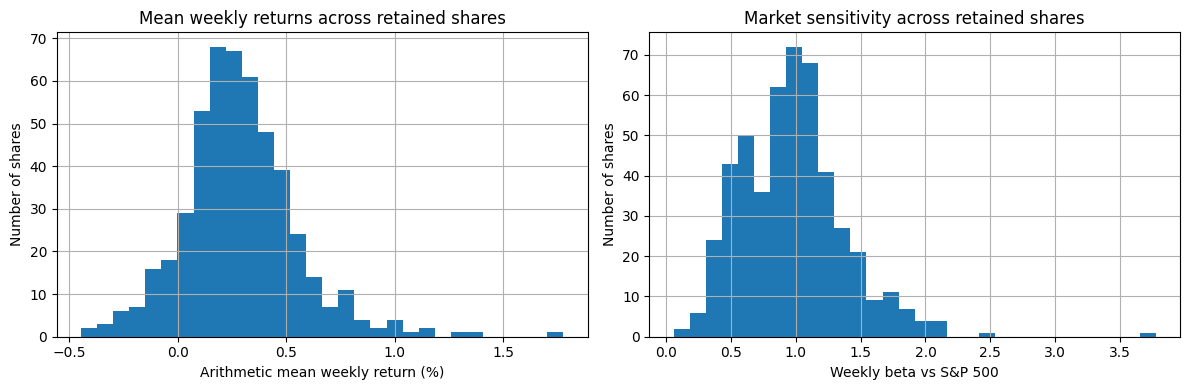

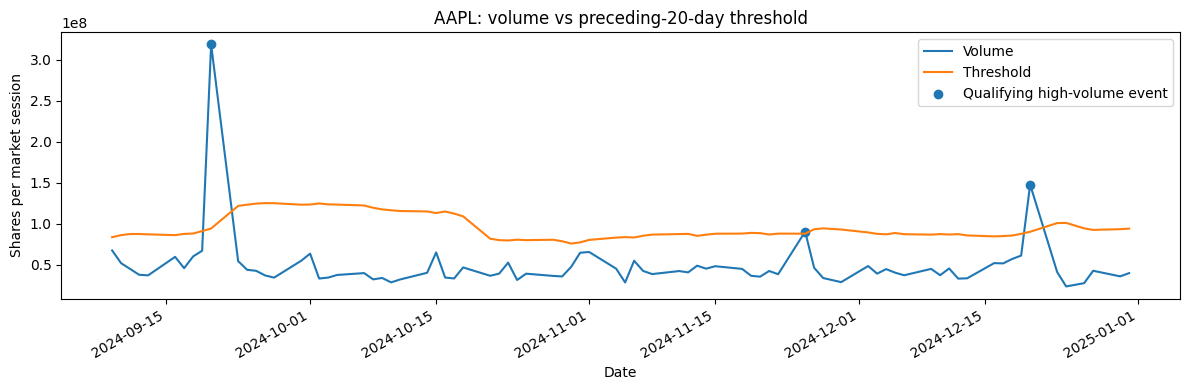

In [18]:
# Task 1.5 - Metric Interpretation and Supporting Visualisations
# Create graphs to help explain the risk, return, and volume measures.
if len(features):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    features['MeanWeeklyReturn'].mul(100).hist(ax=axes[0], bins=30)
    axes[0].set(xlabel='Arithmetic mean weekly return (%)', ylabel='Number of shares',
                title='Mean weekly returns across retained shares')
    features['WeeklyBeta'].hist(ax=axes[1], bins=30)
    axes[1].set(xlabel='Weekly beta vs S&P 500', ylabel='Number of shares',
                title='Market sensitivity across retained shares')
    plt.tight_layout(); plt.savefig(OUT / 'risk_return_feature_distributions.png', dpi=150); plt.show()

if example_timeline is not None and not example_timeline.empty:
    ex = example_timeline.iloc[-80:]
    ax = ex[['Volume','Threshold']].plot(figsize=(12, 4), title=f'{example_ticker}: volume vs preceding-20-day threshold')
    highlighted = ex.loc[ex['HighVolumeEvent']]
    ax.scatter(highlighted.index, highlighted['Volume'], marker='o', label='Qualifying high-volume event')
    ax.set_ylabel('Shares per market session')
    ax.legend(); plt.tight_layout()
    plt.savefig(OUT / f'{example_ticker}_volume_threshold.png', dpi=150); plt.show()

In [19]:
# Task 1 - Save Outputs for Task 1 Submission
# Export the calculated tables, audit logs, and charts into one ZIP file.
# Package the outputs produced by the REAL Colab run for your own inspection and archive.
import shutil
zip_file = shutil.make_archive(str(OUT), 'zip', root_dir=OUT)
print('Archive created:', zip_file)
print('Required audit artifacts:')
for p in sorted(OUT.glob('*')):
    print(f'- {p.name}: {p.stat().st_size/1024:.1f} KB')

Archive created: /content/task1_outputs.zip
Required audit artifacts:
- AAPL_rfm_worked_example_80_sessions.csv: 7.2 KB
- AAPL_volume_threshold.png: 91.2 KB
- daily_quotes_original.csv.gz: 12927.6 KB
- daily_quotes_valid.csv.gz: 12927.6 KB
- daily_validation_audit.csv: 57.7 KB
- duplicate_date_rows.csv: 0.1 KB
- invalid_daily_rows.csv: 0.1 KB
- price_jumps_review.csv: 0.6 KB
- rfm_features_all_shares.csv: 23.9 KB
- risk_return_feature_distributions.png: 55.3 KB
- run_metadata.json: 0.4 KB
- share_inclusion_and_exclusion_log.csv: 93.7 KB
- sp500_constituents_snapshot.csv: 18.9 KB
- task1_common_feature_table.csv: 90.2 KB
- ticker_source.json: 0.2 KB
- weekly_adjusted_price.csv: 1830.1 KB
- weekly_returns.csv: 2109.5 KB
- weekly_risk_features.csv: 23.6 KB
